In [25]:
import numpy as np 
import pandas as pd 
import json
import matplotlib.pyplot as plt
import seaborn as sns

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))



/kaggle/input/datasets/mervebzn/tmdb-5000-movies/tmdb_5000_movies.csv
/kaggle/input/datasets/mervebzn/tmdb-5000-credits/tmdb_5000_credits.csv


In [26]:
PATH_MOVIES  = '/kaggle/input/datasets/mervebzn/tmdb-5000-movies/tmdb_5000_movies.csv'
PATH_CREDITS = '/kaggle/input/datasets/mervebzn/tmdb-5000-credits/tmdb_5000_credits.csv'

df_raw = pd.read_csv(PATH_MOVIES)
credits= pd.read_csv(PATH_CREDITS)

print("Movies: ",df_raw.shape, "\nCredits: ", credits.shape )
print(df_raw.head(3))
print("\n -------------------------------\n",credits.head(3))

Movies:  (4803, 20) 
Credits:  (4803, 4)
      budget                                             genres  \
0  237000000  [{"id": 28, "name": "Action"}, {"id": 12, "nam...   
1  300000000  [{"id": 12, "name": "Adventure"}, {"id": 14, "...   
2  245000000  [{"id": 28, "name": "Action"}, {"id": 12, "nam...   

                                       homepage      id  \
0                   http://www.avatarmovie.com/   19995   
1  http://disney.go.com/disneypictures/pirates/     285   
2   http://www.sonypictures.com/movies/spectre/  206647   

                                            keywords original_language  \
0  [{"id": 1463, "name": "culture clash"}, {"id":...                en   
1  [{"id": 270, "name": "ocean"}, {"id": 726, "na...                en   
2  [{"id": 470, "name": "spy"}, {"id": 818, "name...                en   

                             original_title  \
0                                    Avatar   
1  Pirates of the Caribbean: At World's End   
2              

In [27]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   budget                4803 non-null   int64  
 1   genres                4803 non-null   object 
 2   homepage              1712 non-null   object 
 3   id                    4803 non-null   int64  
 4   keywords              4803 non-null   object 
 5   original_language     4803 non-null   object 
 6   original_title        4803 non-null   object 
 7   overview              4800 non-null   object 
 8   popularity            4803 non-null   float64
 9   production_companies  4803 non-null   object 
 10  production_countries  4803 non-null   object 
 11  release_date          4802 non-null   object 
 12  revenue               4803 non-null   int64  
 13  runtime               4801 non-null   float64
 14  spoken_languages      4803 non-null   object 
 15  status               

In [28]:
credits.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   movie_id  4803 non-null   int64 
 1   title     4803 non-null   object
 2   cast      4803 non-null   object
 3   crew      4803 non-null   object
dtypes: int64(1), object(3)
memory usage: 150.2+ KB


In [29]:
pd.options.display.float_format = '{:,.2f}'.format

print('Numeric Summary --------------\n', df_raw[['budget', 'revenue', 'runtime', 'vote_average', 'vote_count']].describe().T)

print('\nZero Values --------------\n', (df_raw[['budget','revenue', 'runtime']] ==0).sum())


Numeric Summary --------------
                 count          mean            std  min        25%  \
budget       4,803.00 29,045,039.88  40,722,391.26 0.00 790,000.00   
revenue      4,803.00 82,260,638.65 162,857,100.94 0.00       0.00   
runtime      4,801.00        106.88          22.61 0.00      94.00   
vote_average 4,803.00          6.09           1.19 0.00       5.60   
vote_count   4,803.00        690.22       1,234.59 0.00      54.00   

                       50%           75%              max  
budget       15,000,000.00 40,000,000.00   380,000,000.00  
revenue      19,170,001.00 92,917,187.00 2,787,965,087.00  
runtime             103.00        118.00           338.00  
vote_average          6.20          6.80            10.00  
vote_count          235.00        737.00        13,752.00  

Zero Values --------------
 budget     1037
revenue    1427
runtime      35
dtype: int64


In [30]:
# Duplicated

df_raw['id'].duplicated().sum()

np.int64(0)

In [31]:
# Movie Status
df_raw['status'].value_counts()

status
Released           4795
Rumored               5
Post Production       3
Name: count, dtype: int64

In [32]:
# Do both files share the same movies?
set(df_raw['id']) == set(credits['movie_id'])

True

# Cleaning

In [33]:
df = df_raw.copy()
df = df.drop(columns=['homepage','overview','tagline','keywords',
                      'original_title','spoken_languages','production_countries',
                      'production_companies'])

In [34]:
# Conver to datetime
df = df_raw.copy()

df['release_date'] = pd.to_datetime(df['release_date'], errors = 'coerce')
df['release_year'] = df['release_date'].dt.year.astype('Int64')
df[['release_date','release_year']]

,release_date,release_year
0,2009-12-10,2009
1,2007-05-19,2007
2,2015-10-26,2015
3,2012-07-16,2012
4,2012-03-07,2012
...,...,...
4798,1992-09-04,1992
4799,2011-12-26,2011
4800,2013-10-13,2013
4801,2012-05-03,2012


In [35]:
# 0 means "unknown" -> NaN so averages are not distorted
for col in ['budget', 'revenue', 'runtime']:
    df[col] = df[col].replace(0, np.nan)

In [36]:
# Check 
print(df.shape)
print(df[['release_date','budget','revenue','runtime']].isna().sum())
print('\n', df['release_year'].min(),'-', df['release_year'].max())

(4803, 21)
release_date       1
budget          1037
revenue         1427
runtime           37
dtype: int64

 1916 - 2017


In [37]:
# Keep only released movies

df= df[df['status'] == 'Released'].copy().reset_index(drop = True)


In [38]:
# If vote_count is 0 the raiting is not real -> Nan
df.loc[df['vote_count'] == 0, 'vote_average'] = np.nan

In [39]:
# Check 
print(df.shape)  
print(df['status'].value_counts())
print(df['vote_average'].isna().sum())

(4795, 21)
status
Released    4795
Name: count, dtype: int64
61


In [40]:
# JSON

def parse_names(text):
    try: 
        return [d['name'] for d in json.loads(text)]
    except Exception:
        return []

df['genre_list'] = df['genres'].apply(parse_names)
df['genre_count'] = df['genre_list'].apply(len)

print(df[['title', 'genres', 'genre_list']].head())
print(df['genre_count'].value_counts().sort_index())

                                      title  \
0                                    Avatar   
1  Pirates of the Caribbean: At World's End   
2                                   Spectre   
3                     The Dark Knight Rises   
4                               John Carter   

                                              genres  \
0  [{"id": 28, "name": "Action"}, {"id": 12, "nam...   
1  [{"id": 12, "name": "Adventure"}, {"id": 14, "...   
2  [{"id": 28, "name": "Action"}, {"id": 12, "nam...   
3  [{"id": 28, "name": "Action"}, {"id": 80, "nam...   
4  [{"id": 28, "name": "Action"}, {"id": 12, "nam...   

                                      genre_list  
0  [Action, Adventure, Fantasy, Science Fiction]  
1                   [Adventure, Fantasy, Action]  
2                     [Action, Adventure, Crime]  
3               [Action, Crime, Drama, Thriller]  
4           [Action, Adventure, Science Fiction]  
genre_count
0      28
1     897
2    1488
3    1522
4     636
5     187
6 

In [41]:
df_genres = (df[['id', 'genre_list']]
                .explode('genre_list')
                .rename(columns={'genre_list': 'genre'})
                .dropna(subset=['genre'])
            )

print(df_genres.shape, df_genres['genre'].nunique())
print(df_genres['genre'].value_counts())

(12144, 2) 20
genre
Drama              2292
Comedy             1718
Thriller           1272
Action             1153
Romance             893
Adventure           790
Crime               696
Science Fiction     534
Horror              519
Family              512
Fantasy             424
Mystery             348
Animation           234
History             197
Music               185
War                 144
Documentary         109
Western              82
Foreign              34
TV Movie              8
Name: count, dtype: int64


# Analyze

In [42]:
# Movies per year
yearly = (df.dropna(subset = ['release_year'])
             .assign(release_year=lambda d: d['release_year'].astype(int))
             .groupby('release_year')
             .agg(movie_count=('id', 'count'))
             .reset_index()
         )

print(yearly.tail(12))
print(yearly.sort_values('movie_count', ascending=False).head(5))

    release_year  movie_count
78          2006          235
79          2007          195
80          2008          227
81          2009          246
82          2010          225
83          2011          221
84          2012          208
85          2013          231
86          2014          238
87          2015          214
88          2016          104
89          2017            1
    release_year  movie_count
81          2009          246
86          2014          238
78          2006          235
85          2013          231
80          2008          227


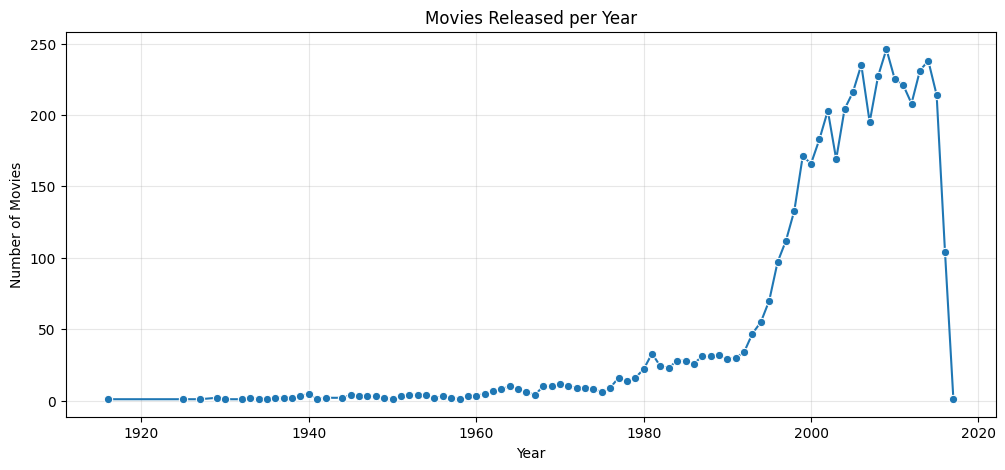

In [43]:
plt.figure(figsize=(12,5))
sns.lineplot(data=yearly, x='release_year', y='movie_count', marker='o')
plt.title('Movies Released per Year')
plt.xlabel('Year'); plt.ylabel('Number of Movies')
plt.grid(alpha=0.3)
plt.show()

In [44]:
# Analysis by genre
gm =df_genres.merge(
    df[['id', 'vote_average', 'vote_count', 'revenue', 'budget', 'runtime', 'release_year']],
    on= 'id', how='left'
)

genre_summary = (gm.groupby('genre')
                    .agg(movie_count= ('id', 'nunique'),
                        avg_rating = ('vote_average', 'mean'),
                         median_rating=('vote_average', 'median'),
                         avg_revenue =('revenue', 'mean'))
                    .sort_values('movie_count', ascending= False)
                        )
genre_summary

,movie_count,avg_rating,median_rating,avg_revenue
genre,,,,
Drama,2292,6.45,6.50,"78,447,013.27"
Comedy,1718,5.99,6.00,"104,566,028.63"
Thriller,1272,6.05,6.10,"107,776,184.28"
Action,1153,6.02,6.10,"173,361,611.19"
Romance,893,6.23,6.30,"88,811,486.00"
Adventure,790,6.16,6.20,"244,209,720.82"
Crime,696,6.32,6.30,"85,737,170.74"
Science Fiction,534,6.02,6.10,"185,795,525.62"
Horror,519,5.69,5.80,"65,697,368.21"


In [48]:
qualified = gm[gm['vote_count'] >= 50].groupby('genre')['id'].nunique().rename('avg_rating_50votes')
genre_summary = genre_summary.join(qualified)
print(genre_summary[['movie_count', 'avg_rating_50votes']])

                 movie_count  avg_rating_50votes
genre                                           
Drama                   2292            1,660.00
Comedy                  1718            1,310.00
Thriller                1272            1,092.00
Action                  1153              975.00
Romance                  893              642.00
Adventure                790              697.00
Crime                    696              604.00
Science Fiction          534              464.00
Horror                   519              430.00
Family                   512              417.00
Fantasy                  424              388.00
Mystery                  348              307.00
Animation                234              203.00
History                  197              152.00
Music                    185              125.00
War                      144              112.00
Documentary              109               36.00
Western                   82               61.00
Foreign             

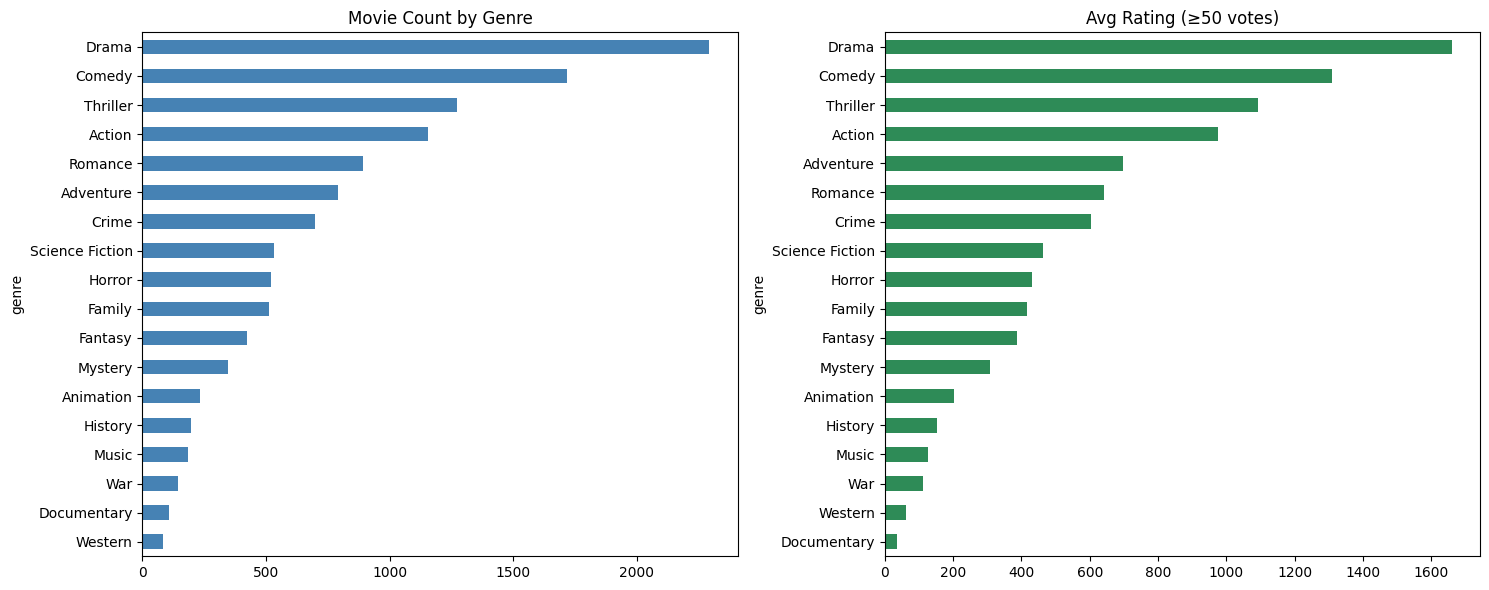

In [49]:
plot_df = genre_summary[genre_summary['qualified_count'] >= 10]

fig, ax =plt.subplots(1, 2, figsize=(15,6))
plot_df['movie_count'].sort_values().plot.barh(ax=ax[0], color='steelblue')
ax[0].set_title('Movie Count by Genre')
plot_df['avg_rating_50votes'].sort_values().plot.barh(ax=ax[1], color='seagreen')
ax[1].set_title('Avg Rating (≥50 votes)')
plt.tight_layout()

plt.show()

In [50]:
# Budget vs revenue

print(df.loc[df['budget']< 10000, ['title', 'budget', 'revenue']].sort_values('budget'))

                               title   budget       revenue
4259           Incident at Loch Ness     1.00           NaN
4420                     Fear Clinic     1.00           NaN
4366                            Slam     1.00           NaN
4290                    The Algerian     1.00           NaN
4244           Me You and Five Bucks     1.00           NaN
4248                   Fetching Cody     1.00           NaN
4235                    Modern Times     1.00  8,500,000.00
4139     To Be Frank, Sinatra at 100     2.00           NaN
3966             Four Single Fathers     3.00           NaN
3686                     Without Men     4.00           NaN
3610              A Farewell to Arms     4.00         25.00
3418                    Bran Nue Dae     7.00          7.00
3371                    Split Second     7.00          5.00
4602                    The Prophecy     8.00         16.00
3130               Of Horses and Men    10.00         11.00
3136                       Nurse 3-D    

In [51]:
df.loc[df['budget']<1000, 'budget'] = np.nan
df.loc[df['revenue'] < 1000, 'revenue'] = np.nan

df_br = df.dropna(subset=['budget', 'revenue']).copy()
print(df_br.shape)

print(df_br[['budget', 'revenue']].corr(method='pearson'))
print(df_br[['budget', 'revenue']].corr(method='spearman'))


(3210, 23)
         budget  revenue
budget     1.00     0.70
revenue    0.70     1.00
         budget  revenue
budget     1.00     0.67
revenue    0.67     1.00


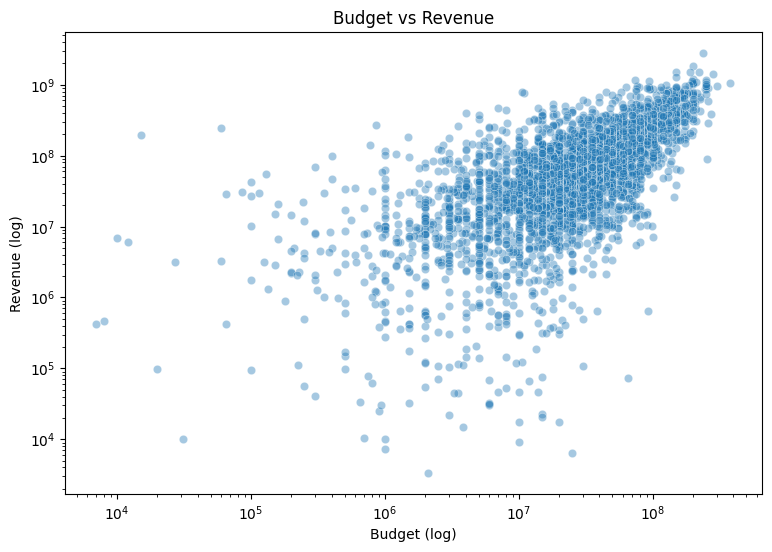

In [52]:
plt.figure(figsize=(9,6))
sns.scatterplot(data=df_br, x='budget', y='revenue', alpha=0.4)
plt.xscale('log')
plt.yscale('log')
plt.title('Budget vs Revenue')
plt.xlabel('Budget (log)')
plt.ylabel('Revenue (log)')

plt.show()

In [53]:
# ROI = revenue / budget; below 1 means a loss
df_br['roi']= df_br['revenue']/ df_br['budget']
print('Loss-making movies %:', round((df_br['roi']< 1).mean() * 100,1))
print(df_br.sort_values('roi', ascending=False)[['title', 'budget', 'revenue', 'roi']].head(8))

Loss-making movies %: 24.3
                             title     budget        revenue       roi
4571           Paranormal Activity  15,000.00 193,355,800.00 12,890.39
4491       The Blair Witch Project  60,000.00 248,000,000.00  4,133.33
4717                    Eraserhead  10,000.00   7,000,000.00    700.00
4780                Pink Flamingos  12,000.00   6,000,000.00    500.00
4735                 Super Size Me  65,000.00  28,575,078.00    439.62
4716                   The Gallows 100,000.00  42,664,410.00    426.64
4508                    Open Water 130,000.00  54,667,954.00    420.52
3158  The Texas Chain Saw Massacre  85,000.00  30,859,000.00    363.05


In [55]:
# Top 10 movies by revenue
top_rev = (df.nlargest(10, 'revenue')
              [['title', 'release_year', 'revenue', 'budget', 'vote_average', 'genre_list']].copy())

top_rev['revenue_m'] = top_rev['revenue'] / 1e6
print(top_rev)

                          title  release_year          revenue         budget  \
0                        Avatar          2009 2,787,965,087.00 237,000,000.00   
25                      Titanic          1997 1,845,034,188.00 200,000,000.00   
16                 The Avengers          2012 1,519,557,910.00 220,000,000.00   
28               Jurassic World          2015 1,513,528,810.00 150,000,000.00   
44                    Furious 7          2015 1,506,249,360.00 190,000,000.00   
7       Avengers: Age of Ultron          2015 1,405,403,694.00 280,000,000.00   
124                      Frozen          2013 1,274,219,009.00 150,000,000.00   
31                   Iron Man 3          2013 1,215,439,994.00 200,000,000.00   
546                     Minions          2015 1,156,730,962.00  74,000,000.00   
26   Captain America: Civil War          2016 1,153,304,495.00 250,000,000.00   

     vote_average                                      genre_list  revenue_m  
0            7.20   [Action, 

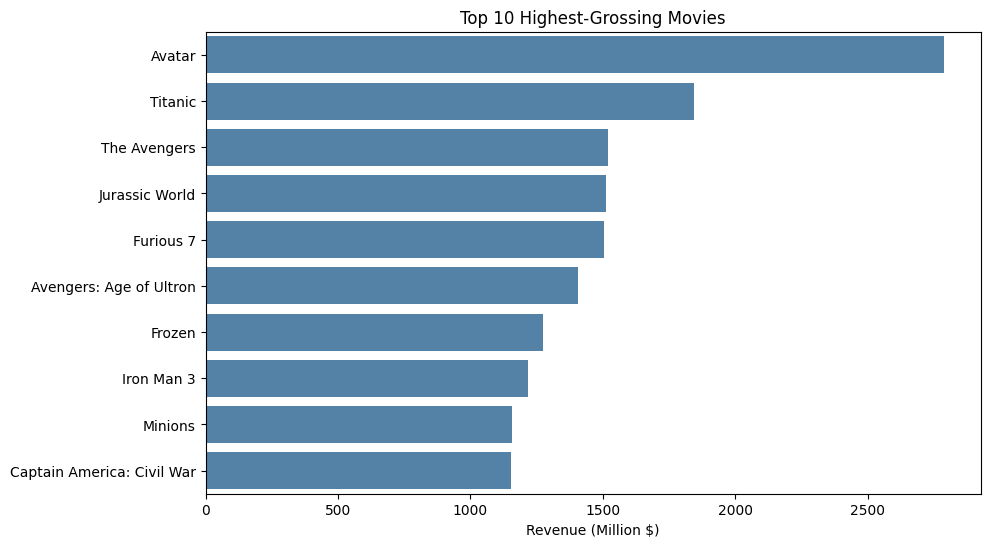

In [56]:
plt.figure(figsize=(10,6))
sns.barplot(data= top_rev, x='revenue_m', y='title', color='steelblue')
plt.title('Top 10 Highest-Grossing Movies')
plt.xlabel('Revenue (Million $)')
plt.ylabel('')

plt.show()

In [57]:
# Top-rated considering vote count
# WR = (v / (v + m)) × R + (m / (v + m)) × C
# v = number of votes for the movie, R = rating of the movie
# m = minimum vote threshold, C = average rating across all movies

rated = df.dropna(subset=['vote_average']).copy()

# C = overall mean rating, m = 90th percentile of vote counts
C = rated['vote_average'].mean()
m = rated['vote_count'].quantile(0.90)
print('C =', round(C, 2), '| m =', round(m))

print(rated.nlargest(10, 'vote_average')[['title', 'vote_average', 'vote_count']])

q = rated[rated['vote_count'] >= m].copy()
q['weighted_rating'] = ((q['vote_count'] / (q['vote_count'] + m)) * q['vote_average']
                        + (m / (q['vote_count'] + m)) * C)

top_rated = q.nlargest(10, 'weighted_rating')[['title', 'release_year', 'vote_average',
                                               'vote_count', 'weighted_rating']]

print(top_rated)

C = 6.17 | m = 1881
                         title  vote_average  vote_count
3518          Stiff Upper Lips         10.00           1
4044     Dancer, Texas Pop. 81         10.00           1
4244     Me You and Five Bucks         10.00           2
3991                 Sardaarji          9.50           2
2386            One Man's Hero          9.30           2
1881  The Shawshank Redemption          8.50        8205
2969        There Goes My Baby          8.50           2
2796     The Prisoner of Zenda          8.40          11
3336             The Godfather          8.40        5893
662                 Fight Club          8.30        9413
                                              title  release_year  \
1881                       The Shawshank Redemption          1994   
662                                      Fight Club          1999   
65                                  The Dark Knight          2008   
3231                                   Pulp Fiction          1994   
96      

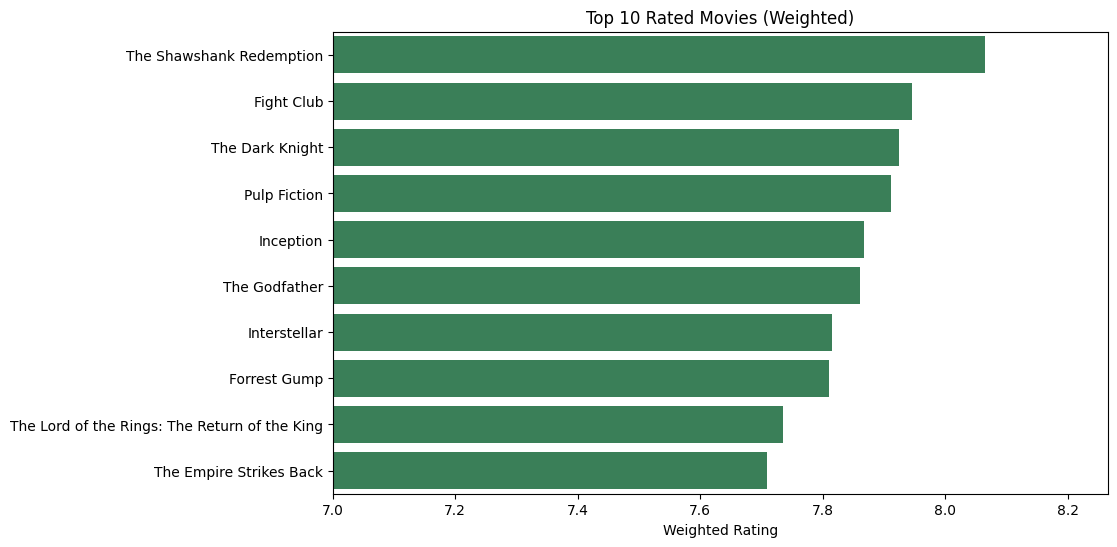

In [58]:
plt.figure(figsize=(10,6))
sns.barplot(data= top_rated, x='weighted_rating', y='title', color='seagreen')
plt.title('Top 10 Rated Movies (Weighted)')
plt.xlabel('Weighted Rating') 
plt.ylabel('')
plt.xlim(7, top_rated['weighted_rating'].max() + 0.2)

plt.show()

In [59]:
print(df[['vote_average', 'vote_count', 'revenue']].corr(method='spearman'))

              vote_average  vote_count  revenue
vote_average          1.00        0.36     0.11
vote_count            0.36        1.00     0.75
revenue               0.11        0.75     1.00


In [61]:
# Revenue and rating over the years
yr = (df.dropna(subset=['release_year'])
        .assign(release_year= lambda d: d['release_year'].astype(int)))
yr= yr[yr['release_year'] <=2015]

trend = yr.groupby('release_year').agg(
    movies=('id', 'count'),
    movies_with_revenue=('revenue', 'count'),
    median_revenue=('revenue', 'median'),
    avg_revenue=('revenue', 'mean')
)

raiting_trend = (yr[yr['vote_count'] >= 50]
                .groupby('release_year')['vote_average']
                .mean()
                .rename('avg_rating')
                )

trend= trend.join(raiting_trend)

trend = trend[trend['movies_with_revenue'] >=10]
print(trend.round(2).tail(10))


              movies  movies_with_revenue  median_revenue    avg_revenue  \
release_year                                                               
2006             235                  169   47,231,070.00  98,437,235.06   
2007             195                  131   62,771,059.00 125,890,240.59   
2008             227                  157   50,907,234.00 115,582,673.90   
2009             246                  160   42,825,822.00 131,704,071.87   
2010             225                  171   49,779,728.00 118,997,513.26   
2011             221                  177   57,777,106.00 115,910,053.26   
2012             208                  149   66,486,080.00 162,024,900.13   
2013             231                  162   63,770,798.50 144,515,390.64   
2014             238                  143   80,383,290.00 168,674,759.36   
2015             214                  126   84,769,058.00 180,754,160.48   

              avg_rating  
release_year              
2006                6.23  
2007  

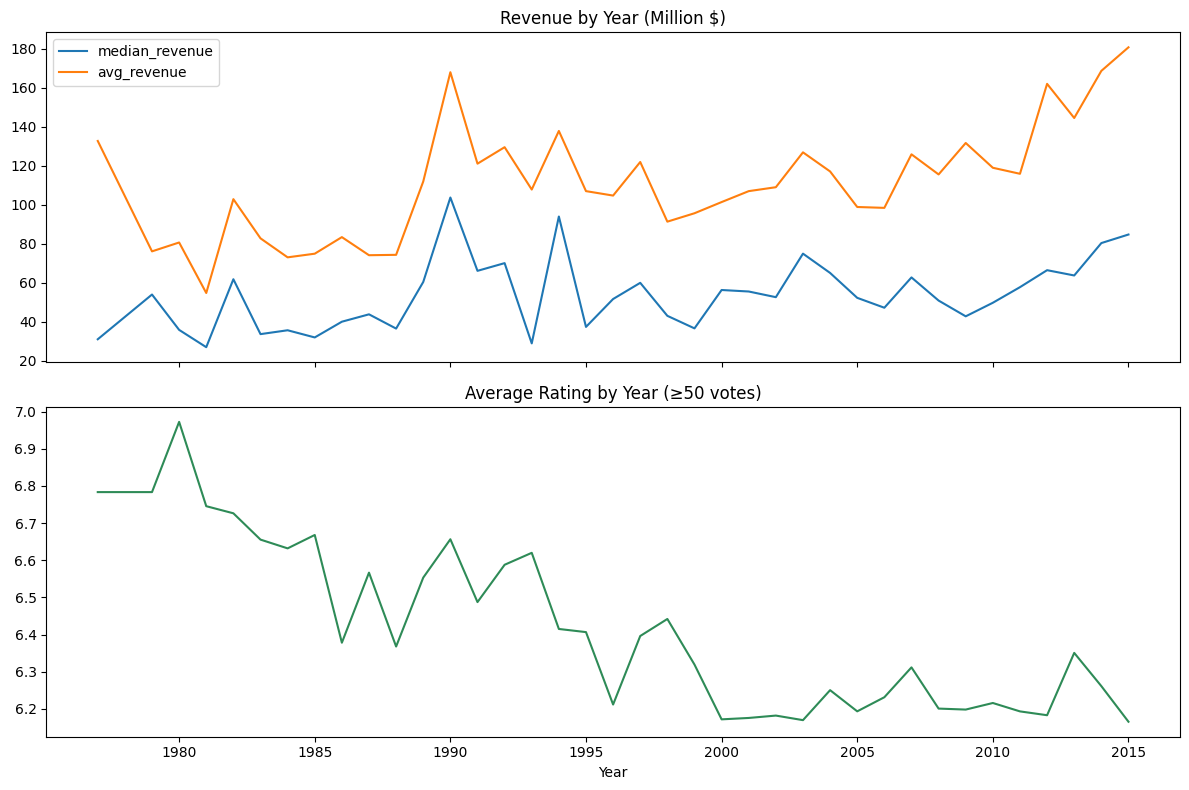

In [63]:
fig, ax = plt.subplots(2,1,figsize=(12,8), sharex= True)
(trend[['median_revenue', 'avg_revenue']] / 1e6).plot(ax=ax[0])
ax[0].set_title('Revenue by Year (Million $)')
trend['avg_rating'].plot(ax=ax[1], color='seagreen')
ax[1].set_title('Average Rating by Year (≥50 votes)')
ax[1].set_xlabel('Year')
plt.tight_layout()

plt.show()


In [71]:
# Runtime analysis 
rt = df.dropna(subset=['runtime']).copy()
print(rt['runtime'].describe())
print('----------------------Largest\n',rt.nlargest(5, 'runtime')[['title', 'runtime']])
print('----------------------Smallest\n',rt.nsmallest(5, 'runtime')[['title', 'runtime']])

rt['runtime_group'] = pd.cut(rt['runtime'], bins=[0, 90, 120, 150, 400],
                             labels=['<90', '90-120', '120-150', '150+'])

rt_group = rt.groupby('runtime_group', observed = True).agg(
    movies= ('id', 'count'),
    avg_rating=('vote_average', 'mean'),
    median_revenue=('revenue', 'median')).round(2)

print('----------------------\n',rt_group)
print('----------------------\n',rt[['runtime', 'vote_average', 'revenue']].corr(method='spearman').round(2))

count   4,759.00
mean      107.68
std        20.76
min        14.00
25%        94.00
50%       104.00
75%       118.00
max       338.00
Name: runtime, dtype: float64
----------------------Largest
             title  runtime
2384       Carlos   338.00
2631  The Company   276.00
1922   Gettysburg   254.00
1125    Cleopatra   248.00
2373       Hamlet   242.00
----------------------Smallest
                                            title  runtime
4461                                      Vessel    14.00
4702                   A Charlie Brown Christmas    25.00
3625  Sea Rex 3D: Journey to a Prehistoric World    41.00
3470    Dolphins and Whales: Tribes of the Ocean    42.00
3353                   Michael Jordan to the Max    46.00
----------------------
                movies  avg_rating  median_revenue
runtime_group                                    
<90               830        5.69   31,070,211.00
90-120           2941        6.12   44,352,417.00
120-150           817        6.68   9

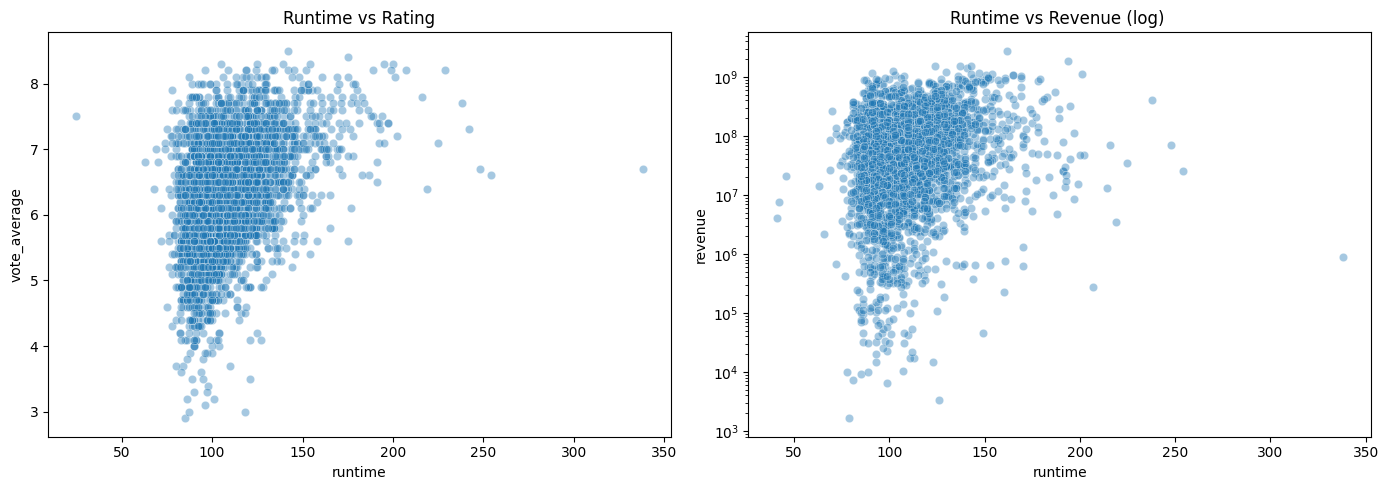

In [70]:
fig, ax = plt.subplots(1, 2, figsize=(14,5))
sns.scatterplot(data = rt[rt['vote_count'] >= 50], x='runtime', y='vote_average', alpha=0.4, ax=ax[0])
ax[0].set_title('Runtime vs Rating')
sns.scatterplot(data=rt.dropna(subset=['revenue']), x='runtime', y='revenue', alpha=0.4, ax=ax[1])
ax[1].set_yscale('log')
ax[1].set_title('Runtime vs Revenue (log) ')
plt.tight_layout()

plt.show()

In [72]:
movies_out = df[['id', 'title', 'release_date', 'release_year', 'budget', 'revenue',
                 'runtime', 'vote_average', 'vote_count', 'popularity',
                 'original_language']].copy()
movies_out['release_year'] = movies_out['release_year'].astype('Int64')   

movies_out.to_csv('movies_clean.csv', index=False)
df_genres.to_csv('movie_genres.csv', index=False)
print(movies_out.shape, df_genres.shape) 

(4795, 11) (12144, 2)
